# 02 — Extract waveforms

Load the 7 pickup waveforms from every chunk into one array each, shape `(n_shots, 960)`.

In [35]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

# PGLA and PKI15A are groups, their trace is in "samples"
WAVEFORMS = {
    "PGIA": "PGIA",
    "PGIP": "PGIP",
    "PGLA": "PGLA/samples",
    "PGRA": "PGRA",
    "PKI15A": "PKI15A/samples",
    "PKI15P": "PKI15P",
    "PKR15A": "PKR15A",
}

In [36]:
waveforms = {name: [] for name in WAVEFORMS}
for path in files:
    with h5py.File(path, "r") as f:
        for name, key in WAVEFORMS.items():
            waveforms[name].append(f[key][:, 0, :])  # (100, 1, 960) -> (100, 960)

waveforms = {name: np.concatenate(arrays) for name, arrays in waveforms.items()}

for name, w in waveforms.items():
    print(f"{name:7s} {w.shape} {w.dtype}")

PGIA    (2100, 960) float64
PGIP    (2100, 960) float64
PGLA    (2100, 960) float64
PGRA    (2100, 960) float64
PKI15A  (2100, 960) float64
PKI15P  (2100, 960) float64
PKR15A  (2100, 960) float64


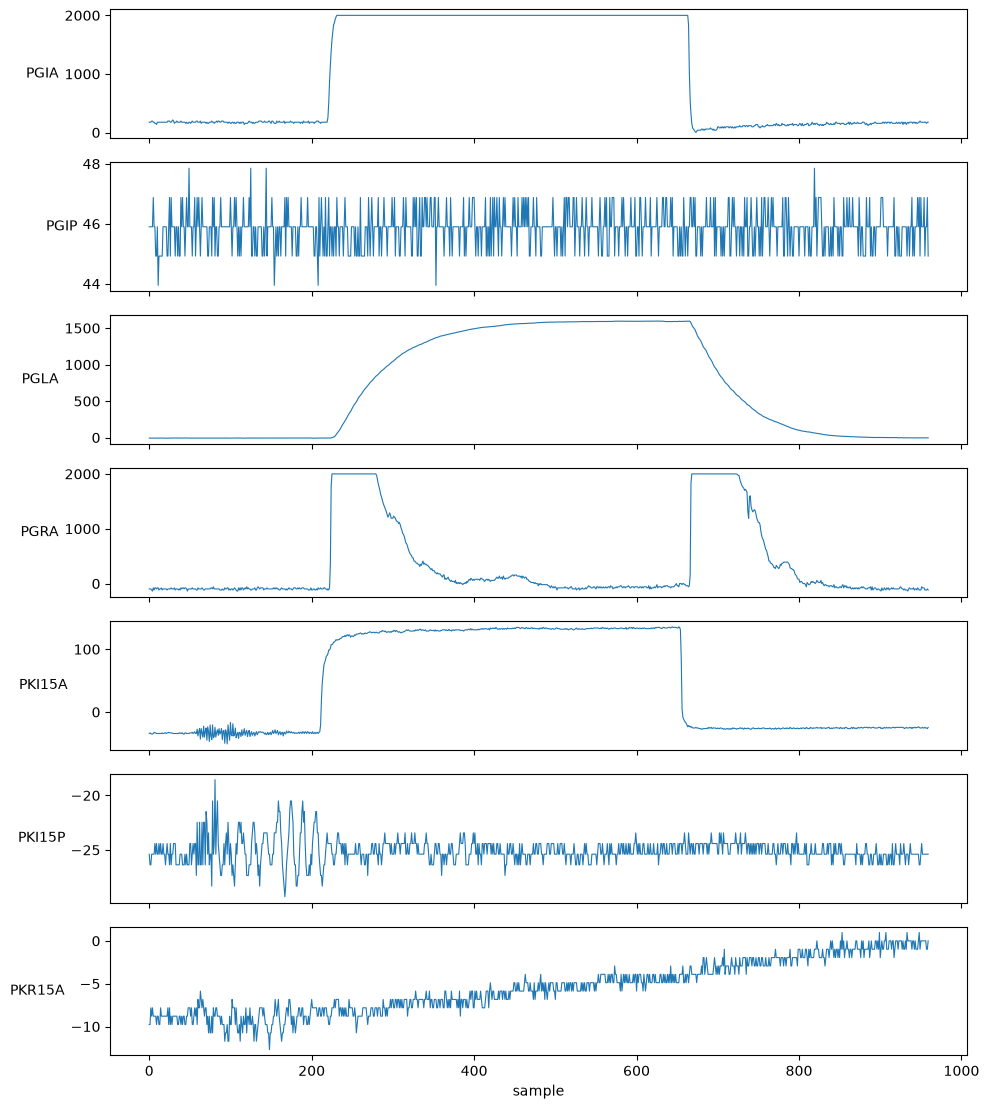

In [37]:
SHOT = 0
fig, axes = plt.subplots(len(waveforms), 1, figsize=(10, 1.6 * len(waveforms)), sharex=True)
for ax, (name, w) in zip(axes, waveforms.items()):
    ax.plot(w[SHOT], lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[-1].set_xlabel("sample")
fig.tight_layout()

## PGLA: drop on the crest

Just before the falling edge (around sample ~632) the crest drops by ~7 mV and stays low until the waveform falls.

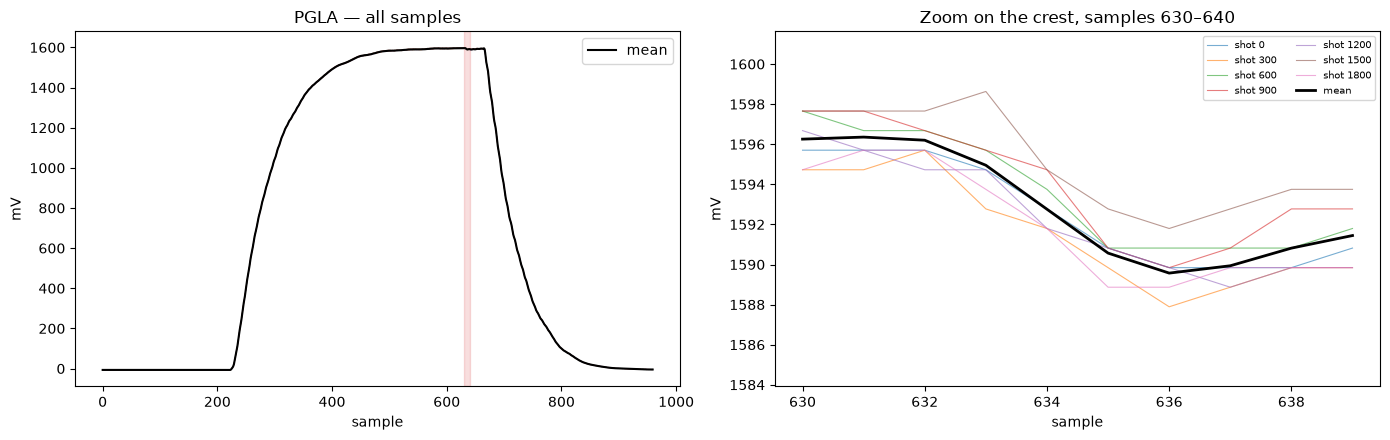

In [38]:
pgla = waveforms["PGLA"]
ZOOM = (630, 640)
SHOTS = range(0, 2100, 300)

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 4.5))

for s in SHOTS:
    ax_full.plot(pgla[s], lw=0.6, alpha=0.6)
    ax_zoom.plot(np.arange(*ZOOM), pgla[s, slice(*ZOOM)], lw=0.8, alpha=0.6, label=f"shot {s}")
ax_full.plot(pgla.mean(axis=0), "k", lw=1.5, label="mean")
ax_zoom.plot(np.arange(*ZOOM), pgla.mean(axis=0)[slice(*ZOOM)], "k", lw=2, label="mean")

ax_full.axvspan(*ZOOM, color="tab:red", alpha=0.15)
ax_full.set(title="PGLA — all samples", xlabel="sample", ylabel="mV")
ax_full.legend()

crest = pgla[list(SHOTS), ZOOM[0]:665]  # stop before the falling edge
ax_zoom.set_ylim(crest.min() - 3, crest.max() + 3)
ax_zoom.set(title=f"Zoom on the crest, samples {ZOOM[0]}–{ZOOM[1]}", xlabel="sample", ylabel="mV")
ax_zoom.legend(fontsize=7, ncol=2)
fig.tight_layout()

## PGLA: size of the drop per shot

Two fixed indices are taken from the **mean waveform**: `I_HIGH` = its max just before the jump (samples 622–632),
`I_LOW` = its min just after it (samples 633–640). For every shot, `drop = pgla[:, I_HIGH] - pgla[:, I_LOW]`.

I_HIGH = 631, I_LOW = 636
drop: median 6.8 mV, 5–95% 4.9–8.8 mV


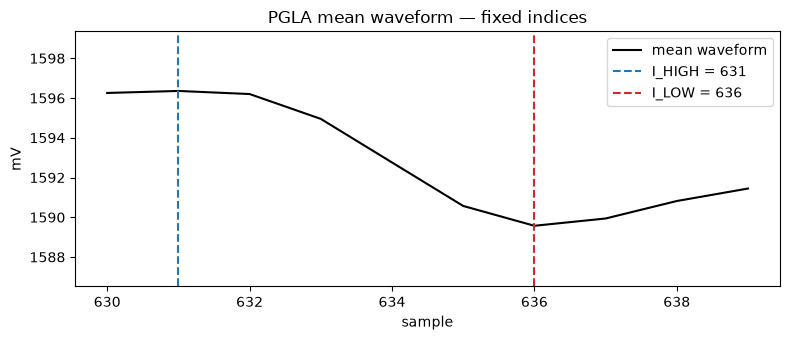

In [39]:
mean_pgla = pgla.mean(axis=0)
I_HIGH = 622 + mean_pgla[622:633].argmax()
I_LOW = 633 + mean_pgla[633:641].argmin()
print(f"I_HIGH = {I_HIGH}, I_LOW = {I_LOW}")

high = pgla[:, I_HIGH]
low = pgla[:, I_LOW]
drop = high - low

print(f"drop: median {np.median(drop):.1f} mV, 5–95% {np.percentile(drop, 5):.1f}–{np.percentile(drop, 95):.1f} mV")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(*ZOOM), mean_pgla[slice(*ZOOM)], "k", lw=1.5, label="mean waveform")
ax.axvline(I_HIGH, color="tab:blue", ls="--", label=f"I_HIGH = {I_HIGH}")
ax.axvline(I_LOW, color="tab:red", ls="--", label=f"I_LOW = {I_LOW}")
ax.set_ylim(mean_pgla[ZOOM[0]:665].min() - 3, mean_pgla[ZOOM[0]:665].max() + 3)
ax.set(xlabel="sample", ylabel="mV", title="PGLA mean waveform — fixed indices")
ax.legend()
fig.tight_layout()

## Drop vs BCM_GUN

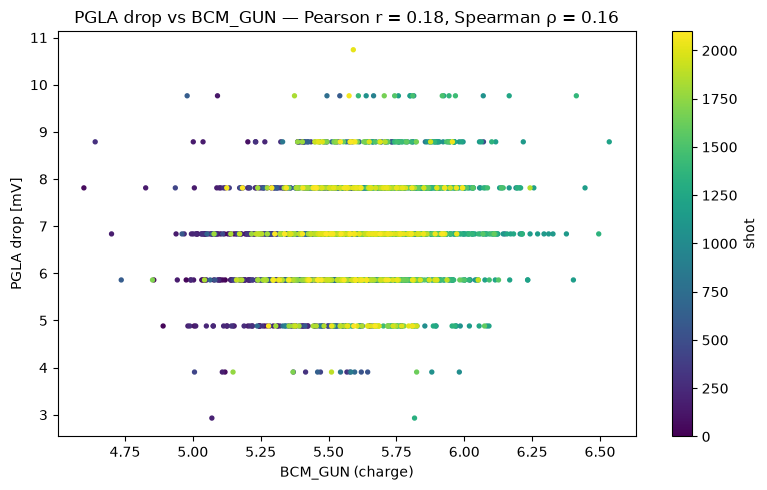

In [40]:
bcm_gun = np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files])


def spearman(x, y):
    return np.corrcoef(x.argsort().argsort(), y.argsort().argsort())[0, 1]


pearson = np.corrcoef(bcm_gun, drop)[0, 1]
rho = spearman(bcm_gun, drop)

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(bcm_gun, drop, c=np.arange(len(drop)), s=8, cmap="viridis")
fig.colorbar(sc, ax=ax, label="shot")
ax.set(xlabel="BCM_GUN (charge)", ylabel="PGLA drop [mV]",
       title=f"PGLA drop vs BCM_GUN — Pearson r = {pearson:.2f}, Spearman ρ = {rho:.2f}")
fig.tight_layout()

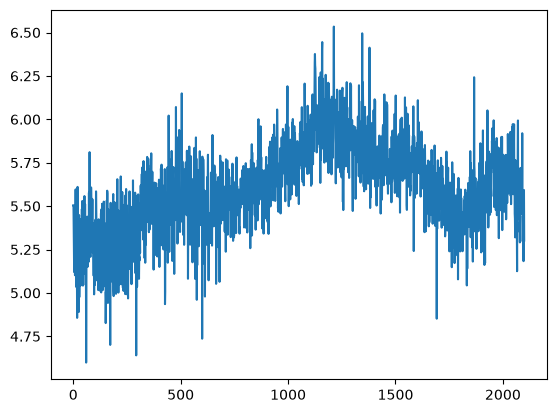

In [41]:
plt.plot(bcm_gun)
plt.show()

## PGIA, PGIP, PGRA: same zoom region as the PGLA crest

Note: PGIA is saturated at ~2000 mV over the whole crest, PGIP is flat noise, and PGRA is still on its baseline
in this region (its pulse starts at ~668).

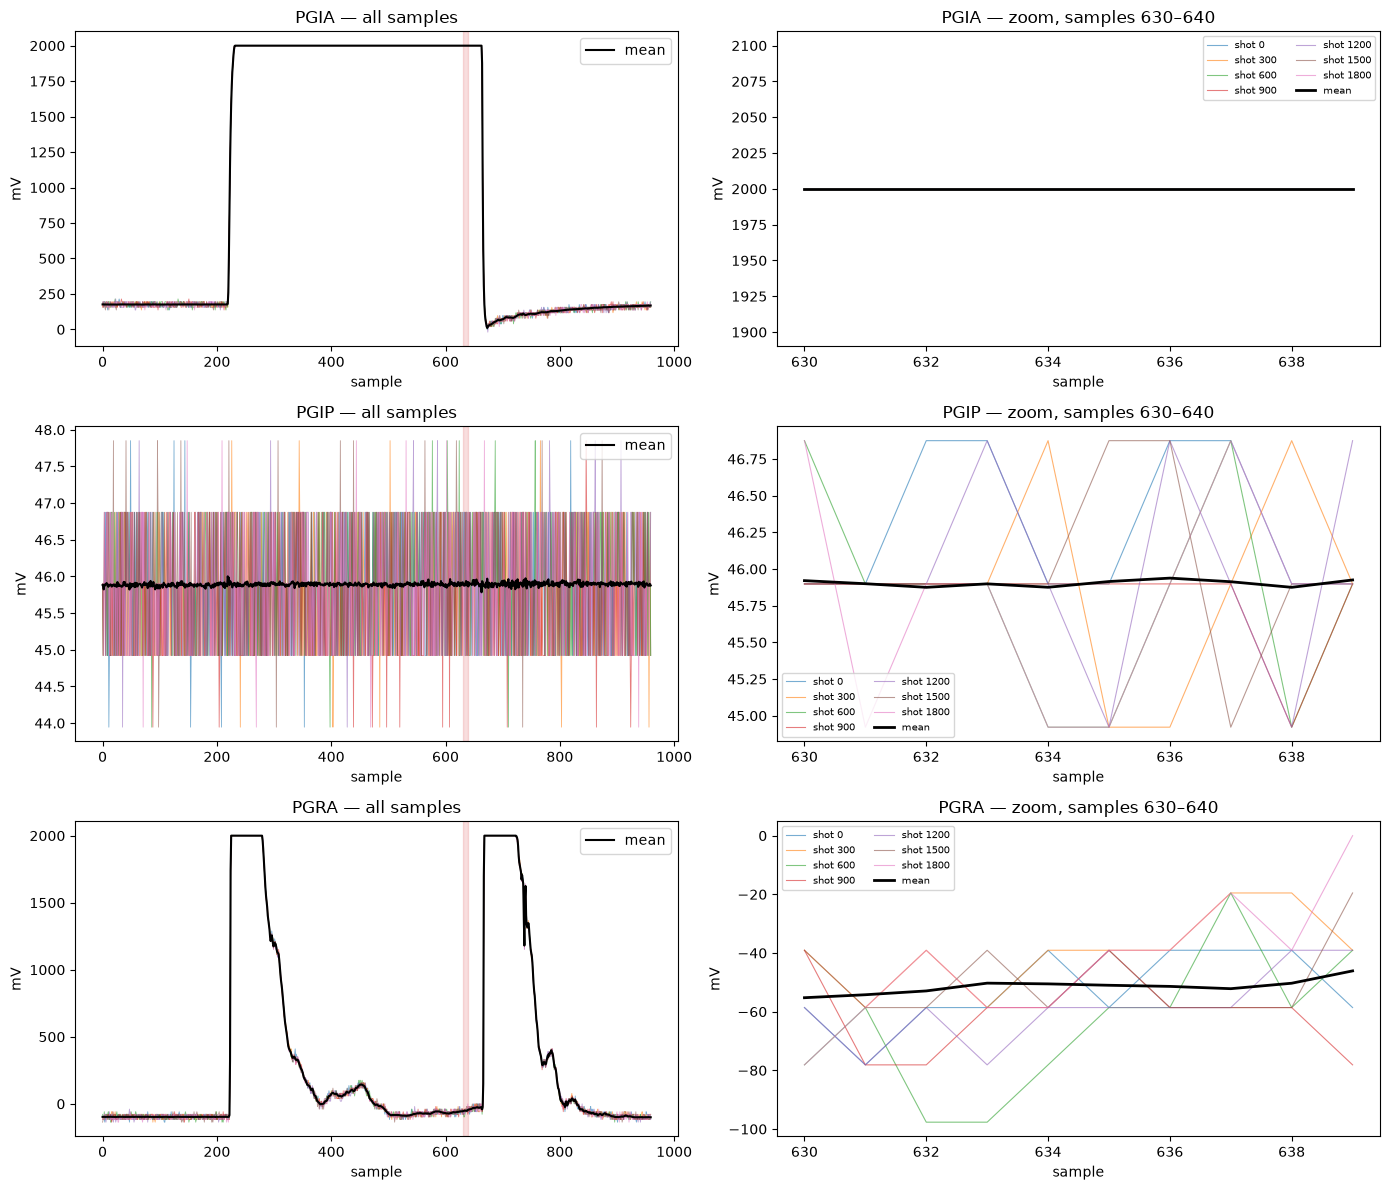

In [42]:
CREST = (630, 640)
names = ["PGIA", "PGIP", "PGRA"]

fig, axes = plt.subplots(len(names), 2, figsize=(14, 4 * len(names)))
for (ax_full, ax_zoom), name in zip(axes, names):
    w = waveforms[name]
    mean_w = w.mean(axis=0)
    x = np.arange(*CREST)
    for s in SHOTS:
        ax_full.plot(w[s], lw=0.6, alpha=0.6)
        ax_zoom.plot(x, w[s, slice(*CREST)], lw=0.8, alpha=0.6, label=f"shot {s}")
    ax_full.plot(mean_w, "k", lw=1.5, label="mean")
    ax_zoom.plot(x, mean_w[slice(*CREST)], "k", lw=2, label="mean")

    ax_full.axvspan(*CREST, color="tab:red", alpha=0.15)
    ax_full.set(title=f"{name} — all samples", xlabel="sample", ylabel="mV")
    ax_full.legend()
    ax_zoom.set(title=f"{name} — zoom, samples {CREST[0]}–{CREST[1]}", xlabel="sample", ylabel="mV")
    ax_zoom.legend(fontsize=7, ncol=2)
fig.tight_layout()

## Klystron traces: PKI15A, PKI15P, PKR15A

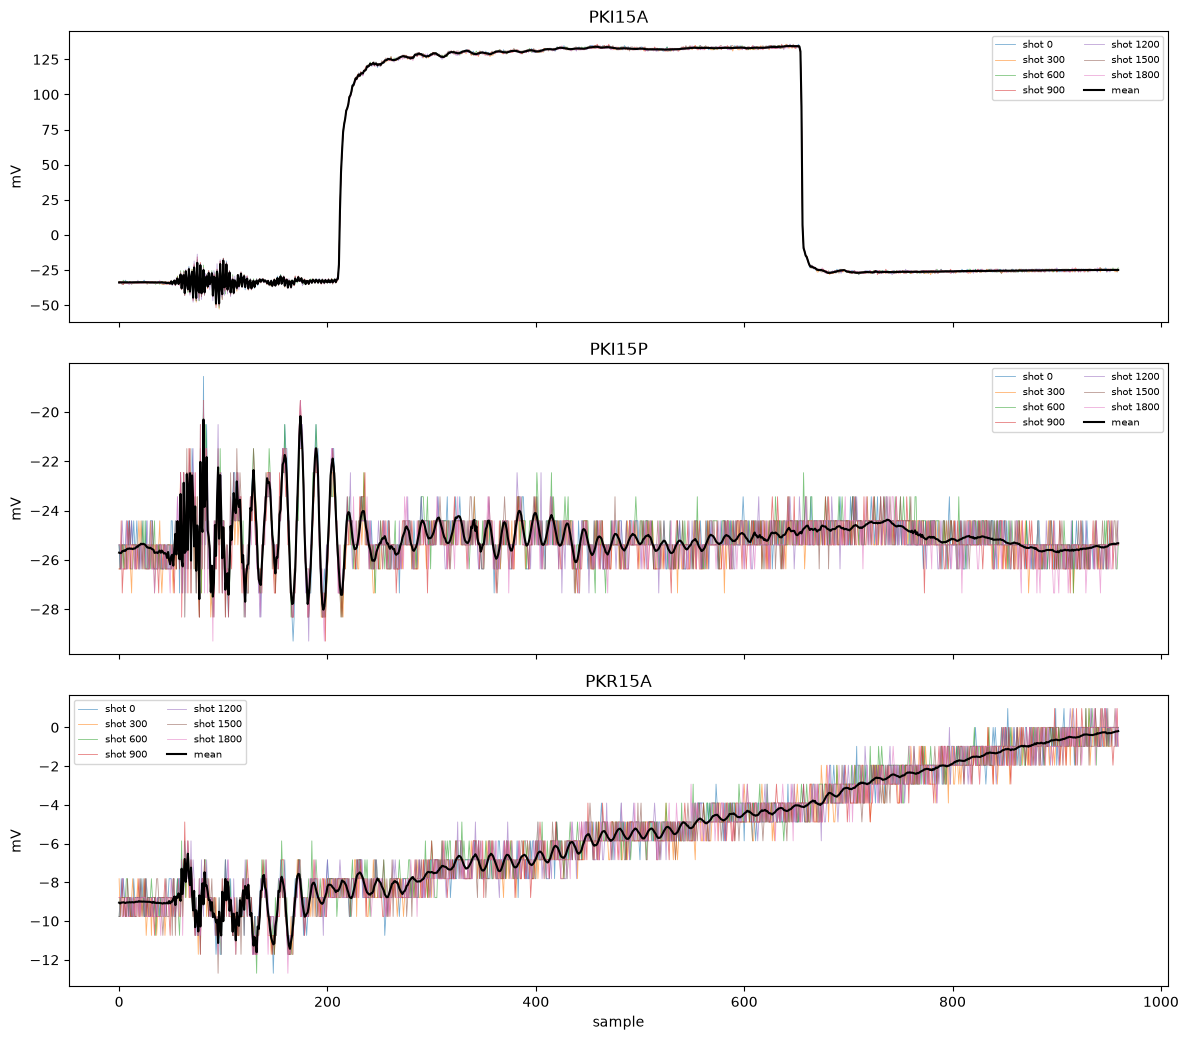

In [43]:
names = ["PKI15A", "PKI15P", "PKR15A"]

fig, axes = plt.subplots(len(names), 1, figsize=(12, 3.5 * len(names)), sharex=True)
for ax, name in zip(axes, names):
    w = waveforms[name]
    for s in SHOTS:
        ax.plot(w[s], lw=0.6, alpha=0.6, label=f"shot {s}")
    ax.plot(w.mean(axis=0), "k", lw=1.5, label="mean")
    ax.set(title=name, ylabel="mV")
    ax.legend(fontsize=7, ncol=2)
axes[-1].set_xlabel("sample")
fig.tight_layout()

## Klystron (MKS) signals vs charge (BCM_GUN)

Four checks, from simple to thorough. Each shot-to-shot check first removes the slow drift (51-shot rolling mean),
because everything drifts during the run and that alone creates correlation. We also scan lags of ±2 shots,
since the laser data turned out to be one shot off from BCM_GUN.

1. **Features** — one number per shot (flat-top amplitude, phase, reflected), lag scan
2. **Per-sample map** — correlation of every sample of the waveform with the charge: where in the pulse is the information?
3. **All samples at once** — ridge regression on the three full waveforms, scored on held-out shots (cross-validated R²)
4. **Slow drift** — rolling means only

PKI15A flat-top mean   relative jitter 0.13%
PKI15P flat-top mean   relative jitter 0.46%
PKR15A flat-top mean   relative jitter 1.74%


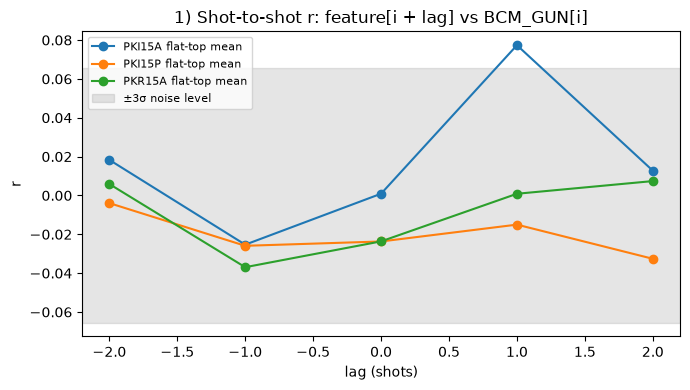

In [44]:
KLYSTRON = ["PKI15A", "PKI15P", "PKR15A"]
FLAT_TOP = slice(300, 640)  # PKI15A pulse is flat between ~300 and ~640
LAGS = np.arange(-2, 3)
N = len(bcm_gun)


def rolling_mean(x, k=51):
    x = np.asarray(x, float)
    padded = np.pad(x, [(k // 2, k // 2)] + [(0, 0)] * (x.ndim - 1), mode="edge")
    c = np.cumsum(np.concatenate([np.zeros((1,) + x.shape[1:]), padded]), axis=0)
    return (c[k:] - c[:-k]) / k


def detrend(x):
    return np.asarray(x, float) - rolling_mean(x)


def lag_corr(x, y, lag):
    """r between x[i + lag] and y[i], after detrending, dropping the wrapped edges."""
    return np.corrcoef(np.roll(detrend(x), -lag, axis=0)[5:-5], detrend(y)[5:-5])[0, 1]


features = {f"{name} flat-top mean": waveforms[name][:, FLAT_TOP].mean(axis=1) for name in KLYSTRON}
for name, f in features.items():
    print(f"{name:22s} relative jitter {f.std() / abs(f.mean()):.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, f in features.items():
    ax.plot(LAGS, [lag_corr(f, bcm_gun, lag) for lag in LAGS], "o-", label=name)
noise = 3 / np.sqrt(N)
ax.axhspan(-noise, noise, color="grey", alpha=0.2, label="±3σ noise level")
ax.set(title="1) Shot-to-shot r: feature[i + lag] vs BCM_GUN[i]", xlabel="lag (shots)", ylabel="r")
ax.legend(fontsize=8)
fig.tight_layout()

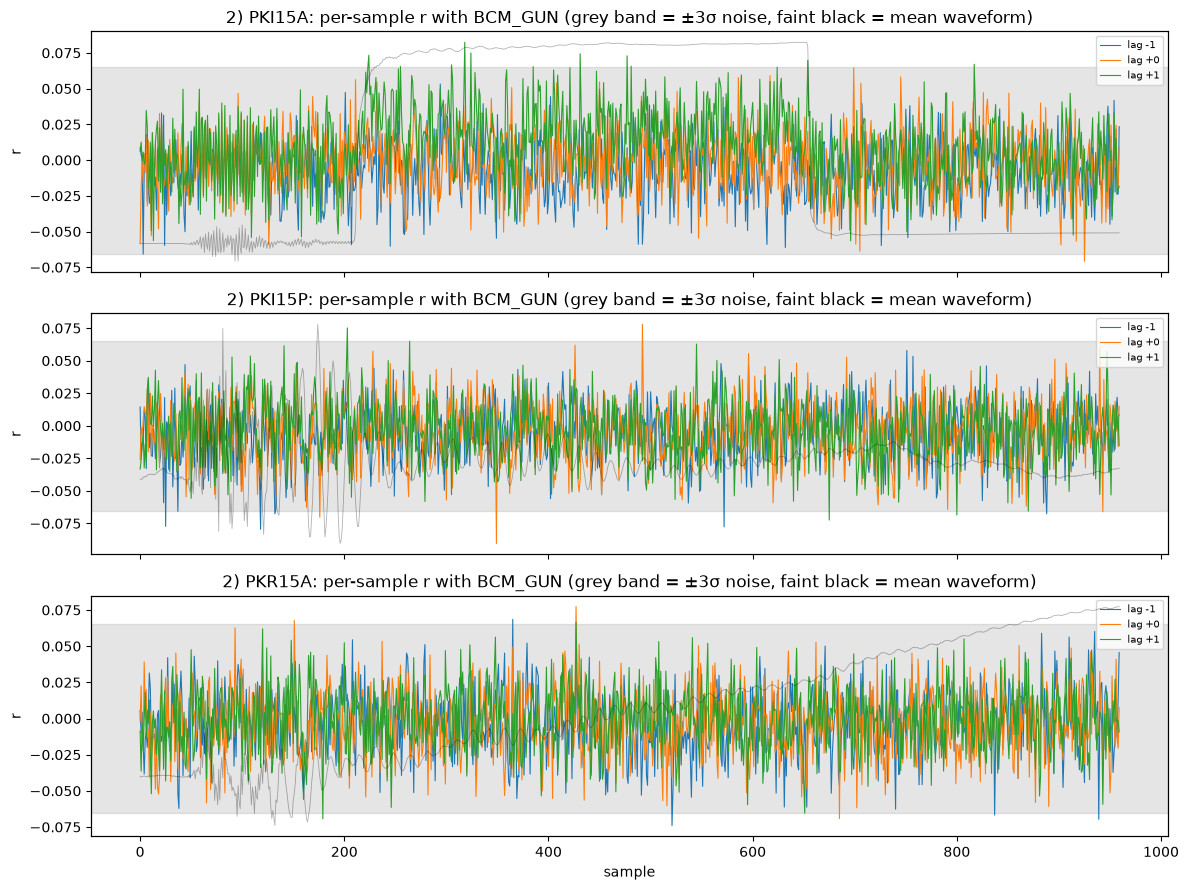

In [45]:
# 2) per-sample correlation map: r(sample) between waveform[i + lag, sample] and BCM_GUN[i]
b = detrend(bcm_gun)[5:-5]
b = (b - b.mean()) / b.std()

fig, axes = plt.subplots(len(KLYSTRON), 1, figsize=(12, 3 * len(KLYSTRON)), sharex=True)
for ax, name in zip(axes, KLYSTRON):
    w = detrend(waveforms[name])
    w = (w - w.mean(axis=0)) / (w.std(axis=0) + 1e-12)
    for lag in (-1, 0, 1):
        r = (np.roll(w, -lag, axis=0)[5:-5] * b[:, None]).mean(axis=0)
        ax.plot(r, lw=0.8, label=f"lag {lag:+d}")
    ax.axhspan(-noise, noise, color="grey", alpha=0.2)
    ax2 = ax.twinx()
    ax2.plot(waveforms[name].mean(axis=0), "k", lw=0.6, alpha=0.3)
    ax2.set_yticks([])
    ax.set(title=f"2) {name}: per-sample r with BCM_GUN (grey band = ±3σ noise, faint black = mean waveform)", ylabel="r")
    ax.legend(fontsize=7, loc="upper right")
axes[-1].set_xlabel("sample")
fig.tight_layout()

In [46]:
# 3) ridge regression on all samples of the three waveforms -> BCM_GUN, cross-validated
X_all = np.hstack([waveforms[name] for name in KLYSTRON])


def cv_r2(X, y, alpha, n_folds=10, gap=60):
    """Contiguous folds with a gap of `gap` shots around each test block, so drift can't leak in."""
    pred = np.empty(len(y))
    for test in np.array_split(np.arange(len(y)), n_folds):
        train = np.setdiff1d(np.arange(len(y)), np.arange(test[0] - gap, test[-1] + gap + 1))
        mu, sd = X[train].mean(axis=0), X[train].std(axis=0) + 1e-9
        U, S, Vt = np.linalg.svd((X[train] - mu) / sd, full_matrices=False)
        w = Vt.T @ (S / (S**2 + alpha) * (U.T @ (y[train] - y[train].mean())))
        pred[test] = (X[test] - mu) / sd @ w + y[train].mean()
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)


rows = []
for target, X, y in [("raw", X_all, bcm_gun), ("detrended", detrend(X_all), detrend(bcm_gun))]:
    for lag in (-1, 0, 1):
        Xl, yl = np.roll(X, -lag, axis=0)[5:-5], y[5:-5]
        best = max(cv_r2(Xl, yl, alpha) for alpha in (1e3, 1e4, 1e5))
        rows.append({"target": target, "lag": lag, "best CV R²": round(best, 3)})
print("R² = 1 is a perfect prediction, R² ≤ 0 means no better than always guessing the mean charge")
for row in rows:
    print(f"{row['target']:10s} lag {row['lag']:+d}   best CV R² = {row['best CV R²']:+.3f}")

R² = 1 is a perfect prediction, R² ≤ 0 means no better than always guessing the mean charge
raw        lag -1   best CV R² = -0.033
raw        lag +0   best CV R² = -0.029
raw        lag +1   best CV R² = -0.030
detrended  lag -1   best CV R² = -0.005
detrended  lag +0   best CV R² = -0.001
detrended  lag +1   best CV R² = +0.002


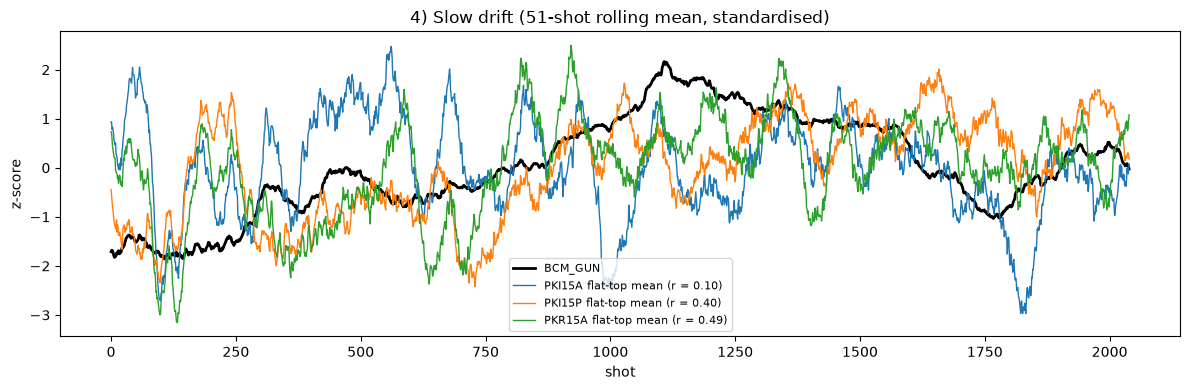

In [47]:
# 4) slow drift only: rolling means over 51 shots
fig, ax = plt.subplots(figsize=(12, 4))
z = lambda x: (x - x.mean()) / x.std()
ax.plot(z(rolling_mean(bcm_gun))[30:-30], "k", lw=2, label="BCM_GUN")
for name, f in features.items():
    r = np.corrcoef(rolling_mean(f)[30:-30], rolling_mean(bcm_gun)[30:-30])[0, 1]
    ax.plot(z(rolling_mean(f))[30:-30], lw=1, label=f"{name} (r = {r:.2f})")
ax.set(title="4) Slow drift (51-shot rolling mean, standardised)", xlabel="shot", ylabel="z-score")
ax.legend(fontsize=8)
fig.tight_layout()